<a href="https://colab.research.google.com/github/anix07/Sales-5444/blob/main/Sales_5444.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42                      # makes results reproducible
DATA_PATH = "Sales-5444.csv"           # place the file next to this notebook
FIG_DIR = "figures/"
os.makedirs(FIG_DIR, exist_ok=True)
results = {}                           # collected for the report

def save(fig_name):
    plt.tight_layout()
    plt.savefig(FIG_DIR + fig_name, dpi=200, bbox_inches="tight")
    plt.show()

In [2]:
# utf-8-sig removes the hidden byte order mark that sits before the first header
# Updated path to match the actual file name '/content/Sales-[5444].csv'
CORRECT_DATA_PATH = "/content/Sales-[5444].csv"
df = pd.read_csv(CORRECT_DATA_PATH, encoding="utf-8-sig")

# Rename columns: fixes the "Catatory" spelling and gives clearer names
df = df.rename(columns={"Item_Name": "brand", "Catatory": "category_raw",
                        "itemLocation": "location"})

print("Rows and columns:", df.shape)
print("\nData types:\n", df.dtypes)
results["raw_shape"] = df.shape

df.head()

Rows and columns: (1000, 10)

Data types:
 brand                 object
details               object
category_raw          object
price                float64
priceWithCurrency     object
available            float64
text                  object
sold                 float64
lastUpdated           object
location              object
dtype: object


,brand,details,category_raw,price,priceWithCurrency,available,text,sold,lastUpdated,location
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


In [3]:
print(df[["price", "available", "sold"]].describe().round(2))
print("\nDistinct brands:", df["brand"].nunique())
print("Distinct category labels:", df["category_raw"].nunique())
print("Distinct locations:", df["location"].nunique())

        price  available      sold
count  995.00     889.00    992.00
mean    46.43      20.05    775.25
std     35.55      61.55   3211.43
min      3.00       2.00      1.00
25%     22.99       5.00     14.00
50%     35.71      10.00     49.50
75%     59.00      10.00    324.75
max    259.09     842.00  54052.00

Distinct brands: 246
Distinct category labels: 63
Distinct locations: 276


In [4]:
print("Missing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
results["missing_raw"] = df.isna().sum().to_dict()

Missing values per column:
 brand                  1
details                0
category_raw           3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
location               0
dtype: int64

Duplicate rows: 0


In [5]:
# Price: recover missing values from the text version (for example "US $109.99")
price_text = (df["priceWithCurrency"].str.extract(r"\$([\d,]+\.?\d*)")[0]
              .str.replace(",", "").astype(float))
df["price"] = df["price"].fillna(price_text)
print("Missing prices after recovery:", df["price"].isna().sum())

# Units sold: parse the listing text and fall back to the numeric column.
# The text value is treated as the source of truth after checking for conflicts.
sold_text = df["text"].str.extract(r"([\d,]+)\s+sold")[0].str.replace(",", "").astype(float)
conflict = (sold_text.notna() & df["sold"].notna() & (sold_text != df["sold"]))
print("Conflicting sold values:", conflict.sum())
df["sold_clean"] = sold_text.fillna(df["sold"])

Missing prices after recovery: 0
Conflicting sold values: 1


In [11]:
# Stock: parse the listing text first, because the numeric column drops digits
# before a thousands separator (for example "1,756" is stored as 756)
avail_text = (df["text"].str.extract(r"^([\d,]+) available")[0]
              .str.replace(",", "").astype(float))
truncated = (avail_text.notna() & df["available"].notna() & (avail_text != df["available"]))
print("Stock values truncated in numeric column:", truncated.sum())

df["available_clean"] = avail_text.fillna(df["available"])
df.loc[df["available_clean"].isna() &
       df["text"].str.contains("Last One", na=False), "available_clean"] = 1  # "Last One" = 1
print("Stock still missing:", df["available_clean"].isna().sum())

# Last updated: parse the timestamp, then convert to days since the newest listing
ts = pd.to_datetime(df["lastUpdated"].str.replace(" PDT", "", regex=False),
                    format="%b %d, %Y %H:%M:%S", errors="coerce")
df["days_since_update"] = (ts.max() - ts).dt.total_seconds() / 86400
print("Update time missing or unreadable:", df["days_since_update"].isna().sum())

Stock values truncated in numeric column: 3
Stock still missing: 64
Update time missing or unreadable: 68


In [12]:
def map_category(x):
    if pd.isna(x):
        return "Generic"
    s = x.lower().strip()
    if "toilette" in s or "toillette" in s or s == "edt":
        return "EDT"
    if "cologne" in s or s == "edc":
        return "Cologne"
    if any(k in s for k in ["parfum", "perfume", "extrait", "elixir", "edp"]):
        return "EDP"
    if re.search(r"body|deodorant|roll|splash|aftershave|\boil\b|freshener", s):
        return "Body"
    return "Generic"

df["category"] = df["category_raw"].apply(map_category)
print(df["category"].value_counts())

category
EDT        463
EDP        394
Cologne     70
Generic     54
Body        19
Name: count, dtype: int64


In [13]:
country = df["location"].str.split(",").str[-1].str.strip()
df["region"] = np.where(country == "United States", "US",
                np.where(country.isin(["Hong Kong", "China", "Taiwan"]), "Asia", "Other"))
print(df["region"].value_counts())

region
US       912
Asia      69
Other     19
Name: count, dtype: int64


In [14]:
# Product size in millilitres, taken from the title (ounces are converted)
def extract_ml(title):
    t = title.lower()
    ml = re.search(r"(\d+(?:\.\d+)?)\s*ml", t)
    if ml:
        return float(ml.group(1))
    oz = re.search(r"(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz", t)
    if oz:
        return float(oz.group(1)) * 29.5735
    return np.nan

df["size_ml"] = df["details"].apply(extract_ml)
df.loc[(df["size_ml"] < 1) | (df["size_ml"] > 500), "size_ml"] = np.nan  # implausible sizes
print("Size not found:", df["size_ml"].isna().sum())

# Set or sampler flag from title keywords
df["is_set"] = df["details"].str.contains(
    r"\bset\b|sampler|\bpcs\b|\d+\s*pc|gift|vials|travel",
    case=False, regex=True).astype(int)
print("Listings flagged as sets:", df["is_set"].sum())

# Brand popularity: number of listings carrying the brand name
df["brand"] = df["brand"].fillna("Unknown")
df["brand_listings"] = df.groupby("brand")["brand"].transform("count")

Size not found: 68
Listings flagged as sets: 39


In [15]:
impute_cols = ["price", "sold_clean", "available_clean", "days_since_update", "size_ml"]
results["imputed_counts"] = df[impute_cols].isna().sum().to_dict()
print("Values imputed:", results["imputed_counts"])

for c in impute_cols:
    df[c] = df[c].fillna(df[c].median())

print("Missing values left:", df[impute_cols].isna().sum().sum())

Values imputed: {'price': 0, 'sold_clean': 0, 'available_clean': 64, 'days_since_update': 68, 'size_ml': 68}
Missing values left: 0


            variable  outliers_raw  outliers_log
0              price            54             5
1         sold_clean           138             4
2    available_clean            98            80
3  days_since_update           131            17
4            size_ml           471           471

Rows with any |z| > 3 on log data: 70


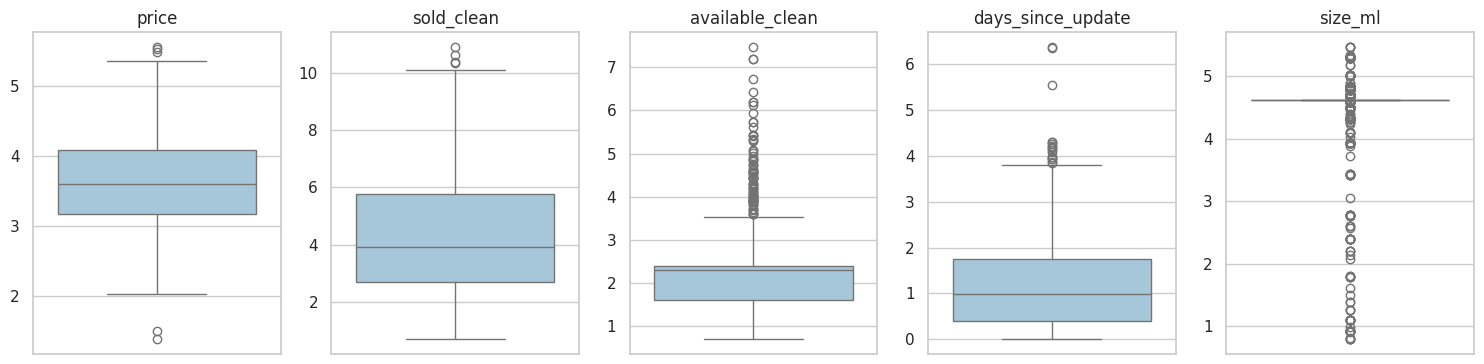

In [16]:
# IQR rule: flags values beyond 1.5 x interquartile range from the quartiles
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

out_table = pd.DataFrame([
    {"variable": c,
     "outliers_raw": int(iqr_outliers(df[c]).sum()),
     "outliers_log": int(iqr_outliers(np.log1p(df[c])).sum())}
    for c in impute_cols])
print(out_table)

# z score rule on log transformed values (|z| > 3)
logs = np.log1p(df[impute_cols + ["brand_listings"]])
z = (logs - logs.mean()) / logs.std()
df["extreme_flag"] = (z.abs() > 3).any(axis=1).astype(int)
print("\nRows with any |z| > 3 on log data:", df["extreme_flag"].sum())

# Visual check: boxplots of log transformed values
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, c in zip(axes, impute_cols):
    sns.boxplot(y=np.log1p(df[c]), ax=ax, color="#9ecae1")
    ax.set_title(c); ax.set_ylabel("")
save("fig00_outliers.png")

results["outliers"] = out_table.to_dict("records")
results["extreme_rows"] = int(df["extreme_flag"].sum())

In [17]:
# Business metric used for profiling only (not a model input)
df["est_revenue"] = df["price"] * df["sold_clean"]

print(df[impute_cols + ["est_revenue"]].describe().round(2).T)
print("\nCategory counts:\n", df["category"].value_counts())

                    count      mean        std   min     25%      50%  \
price              1000.0     46.48      35.53   3.0   22.99    35.71   
sold_clean         1000.0    761.97    3191.83   1.0   14.00    49.50   
available_clean    1000.0     21.44      95.28   1.0    4.00     9.00   
days_since_update  1000.0      6.58      28.36   0.0    0.48     1.71   
size_ml            1000.0     99.03      40.38   1.2  100.00   100.55   
est_revenue        1000.0  25838.36  101906.02  12.0  526.83  1890.50   

                        75%         max  
price                 59.00      259.09  
sold_clean           313.75    54052.00  
available_clean       10.00     1756.00  
days_since_update      4.81      581.67  
size_ml              100.55      236.59  
est_revenue        10937.26  1420246.15  

Category counts:
 category
EDT        463
EDP        394
Cologne     70
Generic     54
Body        19
Name: count, dtype: int64


In [18]:
skew_cols = ["price", "sold_clean", "available_clean", "days_since_update",
             "size_ml", "brand_listings"]

# log1p = log(1 + x): reduces right skew and handles values of zero safely
for c in skew_cols:
    df["log_" + c] = np.log1p(df[c])
log_cols = ["log_" + c for c in skew_cols]

skew_table = pd.DataFrame({"skew before": df[skew_cols].skew().values,
                           "skew after": df[log_cols].skew().values},
                          index=skew_cols).round(2)
print(skew_table)
results["skew_before"] = skew_table["skew before"].to_dict()
results["skew_after"] = dict(zip(log_cols, skew_table["skew after"]))

                   skew before  skew after
price                     2.04        0.11
sold_clean                9.82        0.54
available_clean          12.58        1.75
days_since_update        16.98        1.12
size_ml                   0.10       -2.96
brand_listings            1.12       -0.02


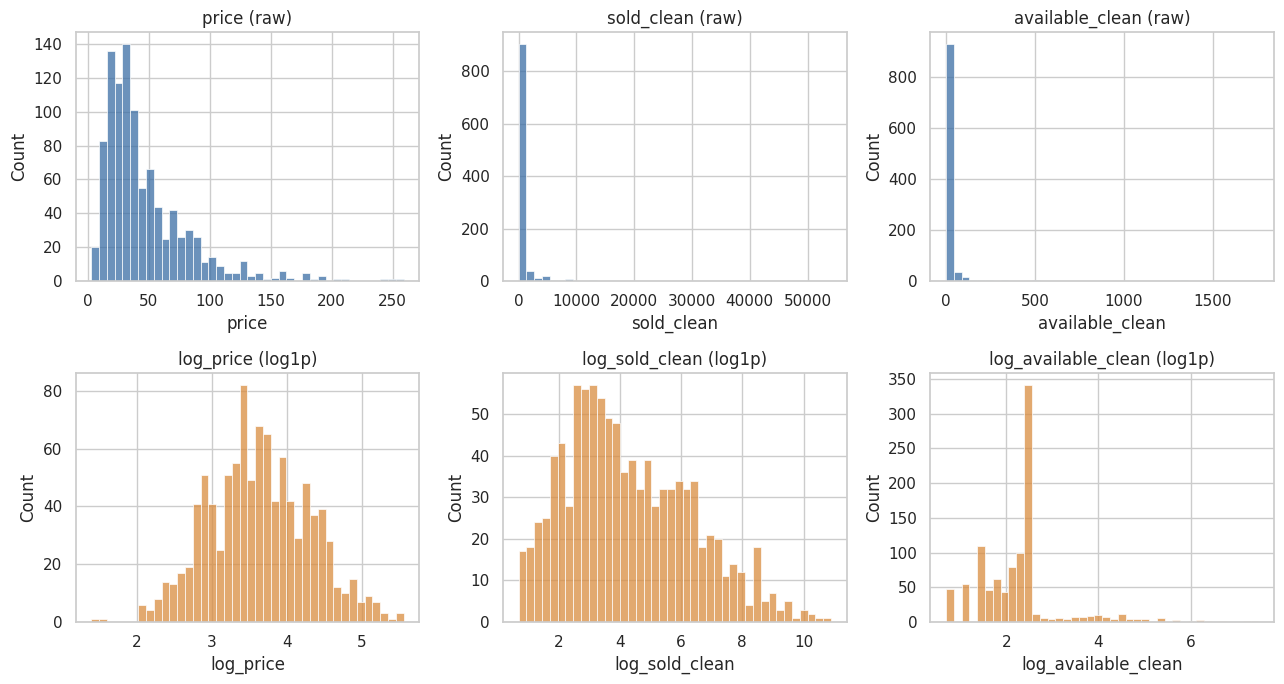

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes[0], ["price", "sold_clean", "available_clean"]):
    sns.histplot(df[c], bins=40, ax=ax, color="#3b6ea5"); ax.set_title(f"{c} (raw)")
for ax, c in zip(axes[1], ["log_price", "log_sold_clean", "log_available_clean"]):
    sns.histplot(df[c], bins=40, ax=ax, color="#d98c3f"); ax.set_title(f"{c} (log1p)")
save("fig01_distributions.png")

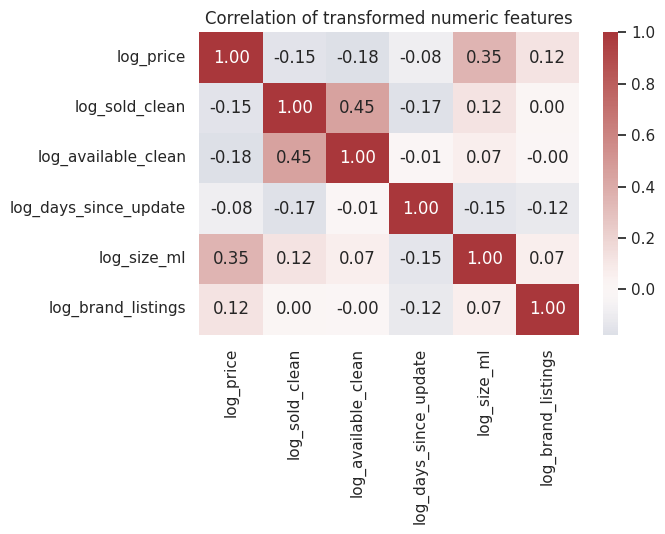

Largest correlation: ('log_sold_clean', 'log_available_clean') 0.45


In [20]:
corr = df[log_cols].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation of transformed numeric features")
save("fig02_correlation.png")
results["corr"] = corr.round(2).to_dict()

off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs().stack()
print("Largest correlation:", off_diag.idxmax(), round(off_diag.max(), 2))

In [21]:
numeric_features = log_cols
categorical_features = ["category", "region"]
binary_features = ["is_set"]

X_cat = pd.get_dummies(df[categorical_features], dtype=float)   # one hot encoding
X_num = df[numeric_features].copy()

scaler = StandardScaler()                                        # zero mean, unit variance
X_num_scaled = pd.DataFrame(scaler.fit_transform(X_num), columns=numeric_features)

X = pd.concat([X_num_scaled,
               X_cat.reset_index(drop=True),
               df[binary_features].reset_index(drop=True).astype(float)], axis=1)
X_values = X.values

print("Feature matrix:", X.shape)
print(list(X.columns))
print("\nScaled numeric check:\n", X_num_scaled.agg(["mean", "std"]).round(2))
results["n_features"] = X.shape[1]
results["feature_names"] = list(X.columns)

Feature matrix: (1000, 15)
['log_price', 'log_sold_clean', 'log_available_clean', 'log_days_since_update', 'log_size_ml', 'log_brand_listings', 'category_Body', 'category_Cologne', 'category_EDP', 'category_EDT', 'category_Generic', 'region_Asia', 'region_Other', 'region_US', 'is_set']

Scaled numeric check:
       log_price  log_sold_clean  log_available_clean  log_days_since_update  \
mean        0.0            -0.0                 -0.0                   -0.0   
std         1.0             1.0                  1.0                    1.0   

      log_size_ml  log_brand_listings  
mean         -0.0                 0.0  
std           1.0                 1.0  


In [22]:
scaling_check = {}
base_labels = None
for name, sc in {"Standard": StandardScaler(), "MinMax": MinMaxScaler(),
                 "Robust": RobustScaler()}.items():
    Xs = np.hstack([sc.fit_transform(X_num), X_cat.values, df[binary_features].values])
    lab = KMeans(4, n_init=20, random_state=RANDOM_STATE).fit_predict(Xs)
    scaling_check[name] = {"silhouette": round(silhouette_score(Xs, lab), 3)}
    if name == "Standard":
        base_labels = lab
    else:
        scaling_check[name]["ARI_vs_Standard"] = round(adjusted_rand_score(base_labels, lab), 3)
print(scaling_check)
results["scaling_check"] = scaling_check

{'Standard': {'silhouette': np.float64(0.174)}, 'MinMax': {'silhouette': np.float64(0.489), 'ARI_vs_Standard': 0.029}, 'Robust': {'silhouette': np.float64(0.741), 'ARI_vs_Standard': 0.114}}


Variance explained by first 5 components: [0.236 0.219 0.145 0.13  0.091]
Cumulative variance, first 8 components: [0.236 0.455 0.6   0.73  0.821 0.897 0.946 0.965]
Components needed for 90% of variance: 7


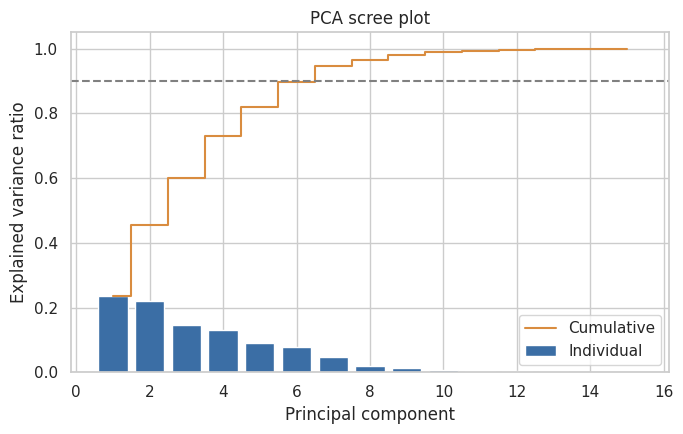

In [23]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_values)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(cum_var >= 0.90) + 1)       # components needed for 90% of variance

print("Variance explained by first 5 components:",
      pca_full.explained_variance_ratio_[:5].round(3))
print("Cumulative variance, first 8 components:", cum_var[:8].round(3))
print("Components needed for 90% of variance:", n90)

results["pca_components_90"] = n90
results["pca_var_first2"] = round(cum_var[1], 3)
results["pca_var_ratio"] = pca_full.explained_variance_ratio_[:5].round(3).tolist()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(1, len(cum_var) + 1), pca_full.explained_variance_ratio_,
       color="#3b6ea5", label="Individual")
ax.step(range(1, len(cum_var) + 1), cum_var, where="mid", color="#d98c3f", label="Cumulative")
ax.axhline(0.90, ls="--", color="grey")           # 90 percent threshold
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("PCA scree plot")
ax.legend()
save("fig03_pca_scree.png")

In [24]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca2.fit_transform(X_values)            # used for the cluster plots in Section 8

loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=["PC1", "PC2"])
print(loadings.round(2))

results["pca_loadings_top"] = {
    pc: loadings[pc].abs().sort_values(ascending=False).head(4).index.tolist()
    for pc in ["PC1", "PC2"]}

                        PC1   PC2
log_price             -0.28  0.59
log_sold_clean         0.67  0.07
log_available_clean    0.62 -0.05
log_days_since_update -0.19 -0.39
log_size_ml            0.12  0.61
log_brand_listings     0.00  0.33
category_Body          0.00 -0.01
category_Cologne       0.00 -0.02
category_EDP          -0.12 -0.00
category_EDT           0.14  0.04
category_Generic      -0.02 -0.00
region_Asia           -0.04  0.02
region_Other          -0.01  0.00
region_US              0.04 -0.02
is_set                -0.01 -0.04


In [25]:
def evaluate(X_, labels):
    mask = labels != -1                      # ignore DBSCAN noise points
    if len(set(labels[mask])) < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(silhouette=silhouette_score(X_[mask], labels[mask]),
                davies_bouldin=davies_bouldin_score(X_[mask], labels[mask]),
                calinski_harabasz=calinski_harabasz_score(X_[mask], labels[mask]))

    silhouette  davies_bouldin  calinski_harabasz   inertia
k                                                          
2        0.148           2.060            178.553  5787.400
3        0.181           1.715            199.366  4873.685
4        0.174           1.693            197.331  4279.326
5        0.169           1.656            188.321  3883.073
6        0.169           1.584            182.875  3553.756
7        0.167           1.498            176.911  3297.730
8        0.162           1.507            166.515  3136.922
9        0.162           1.556            156.234  3017.319
10       0.152           1.643            147.219  2917.787


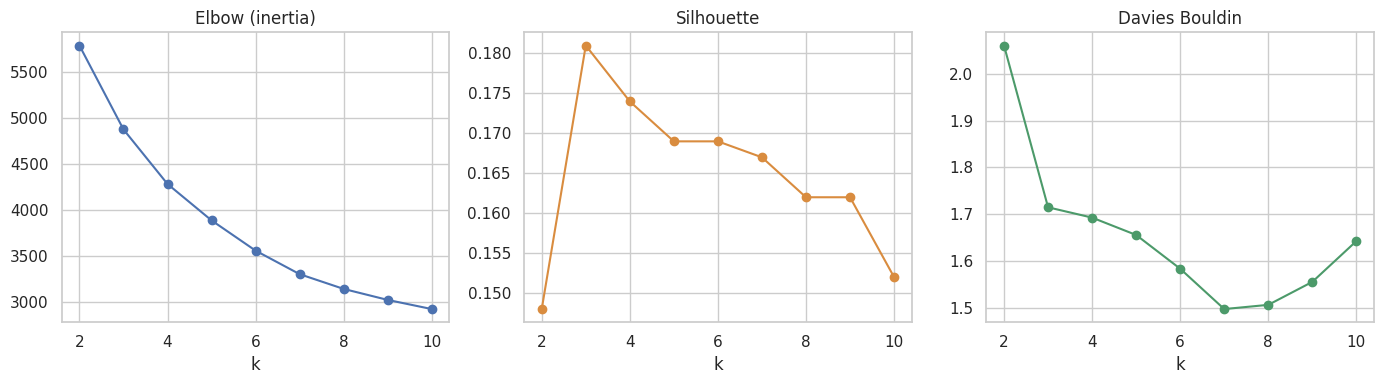

Selected k: 3
km_label
0    341
1    582
2     77
Name: count, dtype: int64


In [26]:
k_range = range(2, 11)
km_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20,
                random_state=RANDOM_STATE).fit(X_values)
    m = evaluate(X_values, km.labels_); m.update(k=k, inertia=km.inertia_)
    km_rows.append(m)
km_table = pd.DataFrame(km_rows).set_index("k").round(3)
print(km_table)
results["kmeans_table"] = km_table.reset_index().to_dict("records")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(km_table.index, km_table["inertia"], "o-");          ax[0].set_title("Elbow (inertia)")
ax[1].plot(km_table.index, km_table["silhouette"], "o-", color="#d98c3f"); ax[1].set_title("Silhouette")
ax[2].plot(km_table.index, km_table["davies_bouldin"], "o-", color="#4c9a6a"); ax[2].set_title("Davies Bouldin")
for a in ax: a.set_xlabel("k")
save("fig04_kmeans_selection.png")

# Business rule: at least three segments so the result is actionable
cand = km_table.loc[3:8]
K_FINAL = int(cand["silhouette"].idxmax())
print("Selected k:", K_FINAL)
results["K_FINAL"] = K_FINAL

kmeans = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=50,
                random_state=RANDOM_STATE).fit(X_values)
df["km_label"] = kmeans.labels_
print(df["km_label"].value_counts().sort_index())

In [27]:
linkage_results = {}
for method in ["ward", "complete", "average"]:
    Z = linkage(X_values, method=method)
    lab = AgglomerativeClustering(n_clusters=K_FINAL, linkage=method).fit_predict(X_values)
    coph, _ = cophenet(Z, pdist(X_values))
    row = evaluate(X_values, lab); row["cophenetic"] = coph
    linkage_results[method] = {k: round(float(v), 3) for k, v in row.items()}
    print(method, "cluster sizes:", np.bincount(lab))
print(pd.DataFrame(linkage_results).T)
results["linkage_results"] = linkage_results

ward cluster sizes: [852  71  77]
complete cluster sizes: [172 778  50]
average cluster sizes: [996   1   3]
          silhouette  davies_bouldin  calinski_harabasz  cophenetic
ward           0.259           1.222            162.391       0.574
complete       0.139           1.860             98.724       0.478
average        0.374           0.773              8.502       0.712


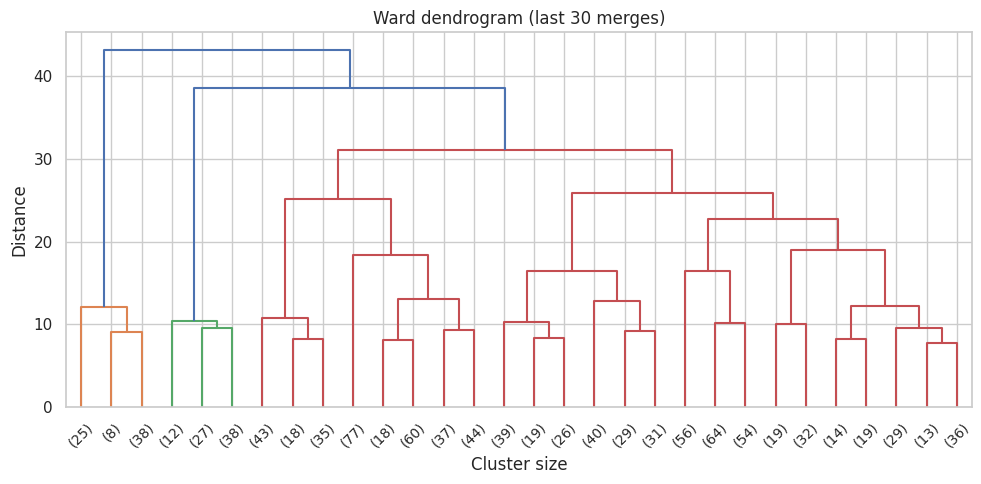

    silhouette  davies_bouldin  calinski_harabasz
k                                                
2        0.326           1.190            157.893
3        0.259           1.222            162.391
4        0.126           1.935            153.657
5        0.122           1.948            143.438
6        0.109           1.868            139.485
7        0.111           1.828            135.652
8        0.116           1.748            129.125
9        0.114           1.721            124.660
10       0.120           1.733            119.857


In [28]:
Z_ward = linkage(X_values, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=30,
           color_threshold=Z_ward[-(K_FINAL - 1), 2])
plt.title("Ward dendrogram (last 30 merges)")
plt.xlabel("Cluster size"); plt.ylabel("Distance")
save("fig05_dendrogram.png")

# Ward for every k, to check the choice of three clusters
hc_rows = []
for k in k_range:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_values)
    m = evaluate(X_values, lab); m["k"] = k; hc_rows.append(m)
hc_table = pd.DataFrame(hc_rows).set_index("k").round(3)
print(hc_table)
results["hc_table"] = hc_table.reset_index().to_dict("records")

hc = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit(X_values)
df["hc_label"] = hc.labels_

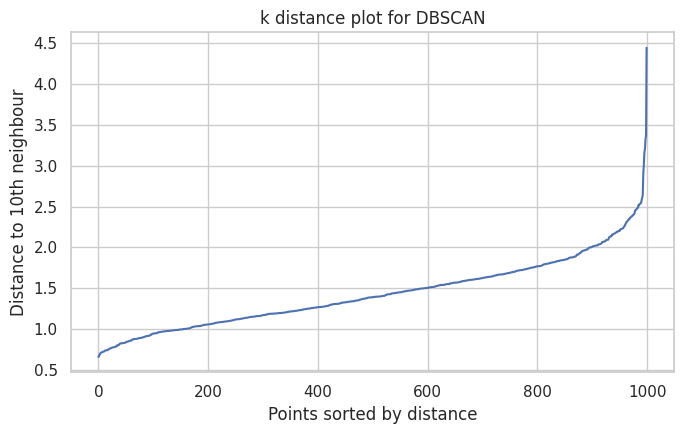

In [29]:
nn = NearestNeighbors(n_neighbors=10).fit(X_values)
dist, _ = nn.kneighbors(X_values)

plt.figure(figsize=(7, 4.5))
plt.plot(np.sort(dist[:, -1]))
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 10th neighbour")
plt.title("k distance plot for DBSCAN")
save("fig06_kdistance.png")

In [30]:
db_rows = []
for eps in np.arange(0.8, 4.01, 0.2):
    for ms in [5, 10, 15, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_values)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        noise = float(np.mean(lab == -1))
        sil = evaluate(X_values, lab)["silhouette"] if n_cl >= 2 else np.nan
        db_rows.append(dict(eps=round(eps, 1), min_samples=ms, clusters=n_cl,
                            noise_pct=round(100 * noise, 1), silhouette=sil))
db_grid = pd.DataFrame(db_rows)
print("Combinations tested:", len(db_grid))
print(db_grid.sort_values("silhouette", ascending=False).head(10).round(3))

# Rule: at least two clusters and no more than 15 percent noise
valid = db_grid[(db_grid.clusters >= 2) & (db_grid.noise_pct <= 15)]
print("Combinations meeting the rule:", len(valid))
best = valid.sort_values("silhouette", ascending=False).iloc[0]
EPS, MINS = float(best.eps), int(best.min_samples)
print("DBSCAN choice: eps =", EPS, "min_samples =", MINS)

dbscan = DBSCAN(eps=EPS, min_samples=MINS).fit(X_values)
df["db_label"] = dbscan.labels_
print(pd.Series(dbscan.labels_).value_counts())

results["dbscan_choice"] = dict(eps=EPS, min_samples=MINS)
results["dbscan_noise_pct"] = round(100 * float(np.mean(dbscan.labels_ == -1)), 1)
results["dbscan_clusters"] = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)

Combinations tested: 68
    eps  min_samples  clusters  noise_pct  silhouette
1   0.8           10         2       91.1       0.438
17  1.6           10         2       13.3       0.415
2   0.8           15         2       95.0       0.413
22  1.8           15         2        7.8       0.401
7   1.0           20         2       86.3       0.392
27  2.0           20         2        4.1       0.379
6   1.0           15         3       81.0       0.311
10  1.2           15         3       57.0       0.158
0   0.8            5        17       74.5       0.154
11  1.2           20         4       65.4       0.130
Combinations meeting the rule: 3
DBSCAN choice: eps = 1.6 min_samples = 10
 0    847
-1    133
 1     20
Name: count, dtype: int64


In [31]:
comparison = pd.DataFrame({
    "K Means": evaluate(X_values, df["km_label"].values),
    "Hierarchical (Ward)": evaluate(X_values, df["hc_label"].values),
    "DBSCAN": evaluate(X_values, df["db_label"].values)}).T

comparison["clusters"] = [df["km_label"].nunique(), df["hc_label"].nunique(),
                          results["dbscan_clusters"]]
comparison["noise_pct"] = [0, 0, results["dbscan_noise_pct"]]
print(comparison.round(3))

# Agreement between K Means and Ward (1 = identical partitions)
results["ARI_km_hc"] = round(adjusted_rand_score(df["km_label"], df["hc_label"]), 3)
print("Agreement K Means vs Ward (ARI):", results["ARI_km_hc"])
results["comparison"] = comparison.round(3).reset_index().to_dict("records")

                     silhouette  davies_bouldin  calinski_harabasz  clusters  \
K Means                   0.181           1.715            199.366         3   
Hierarchical (Ward)       0.259           1.222            162.391         3   
DBSCAN                    0.415           0.764             80.091         2   

                     noise_pct  
K Means                    0.0  
Hierarchical (Ward)        0.0  
DBSCAN                    13.3  
Agreement K Means vs Ward (ARI): 0.294


In [32]:
rng = np.random.RandomState(RANDOM_STATE)
stab = {"K Means": [], "Hierarchical (Ward)": []}
for _ in range(30):
    idx = rng.choice(len(X_values), int(0.8 * len(X_values)), replace=False)
    km_s = KMeans(K_FINAL, n_init=10,
                  random_state=int(rng.randint(1e6))).fit_predict(X_values[idx])
    hc_s = AgglomerativeClustering(K_FINAL, linkage="ward").fit_predict(X_values[idx])
    stab["K Means"].append(adjusted_rand_score(df["km_label"].values[idx], km_s))
    stab["Hierarchical (Ward)"].append(adjusted_rand_score(df["hc_label"].values[idx], hc_s))

results["stability_ARI"] = {k: [round(float(np.mean(v)), 3), round(float(np.std(v)), 3)]
                            for k, v in stab.items()}
print(results["stability_ARI"])

{'K Means': [0.932, 0.109], 'Hierarchical (Ward)': [0.657, 0.293]}


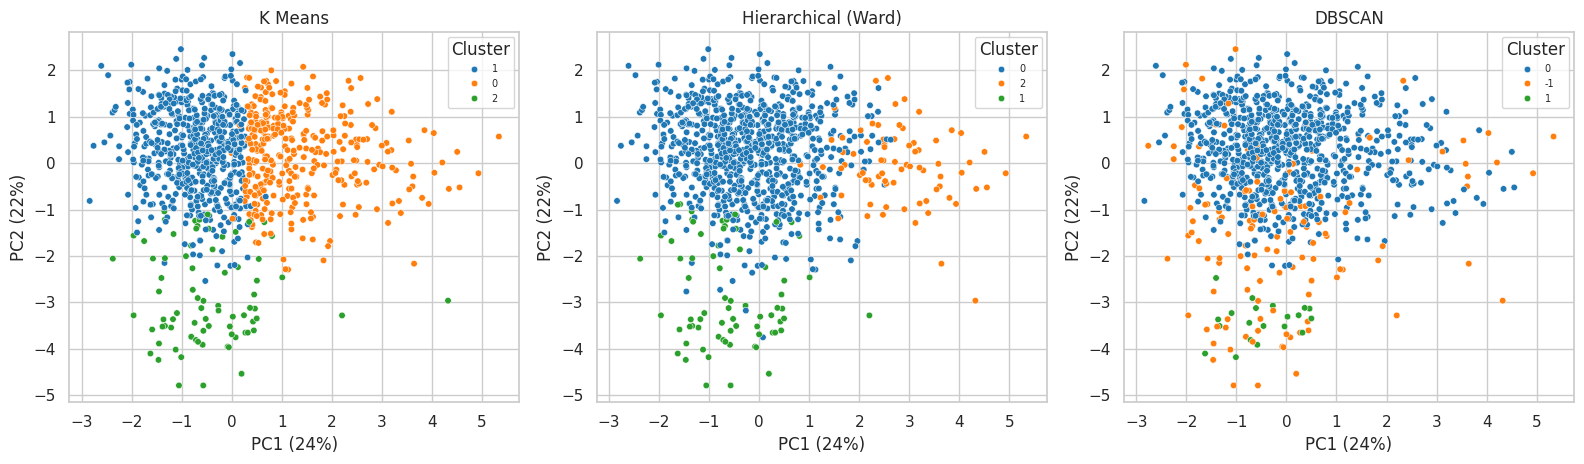

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, col) in zip(axes, [("K Means", "km_label"),
                                  ("Hierarchical (Ward)", "hc_label"),
                                  ("DBSCAN", "db_label")]):
    sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=df[col].astype(str),
                    palette="tab10", s=22, ax=ax, legend="full")
    ax.set_title(name)
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%})")
    ax.legend(title="Cluster", fontsize=7, loc="best")
save("fig07_pca_clusters.png")

In [34]:
def refit_without(mask_remove, label):
    keep = ~mask_remove
    ref = KMeans(K_FINAL, init="k-means++", n_init=50,
                 random_state=RANDOM_STATE).fit(X_values[keep])
    ari = adjusted_rand_score(df.loc[keep, "km_label"].values, ref.labels_)
    print(f"{label}: removed {mask_remove.sum()}, ARI = {ari:.3f}")
    print(pd.crosstab(df.loc[keep, "km_label"].values, ref.labels_,
                      rownames=["full model"], colnames=["refit"]))
    return ari

# Version 1: every row flagged in Section 4.6 (any variable, including size)
all_flag = df["extreme_flag"].values == 1
ari_all = refit_without(all_flag, "All flagged rows")

# Version 2: rows flagged on commercial variables only (size left in)
com_cols = ["price", "sold_clean", "available_clean", "days_since_update"]
logs_c = np.log1p(df[com_cols])
z_c = (logs_c - logs_c.mean()) / logs_c.std()
com_flag = (z_c.abs() > 3).any(axis=1).values
ari_com = refit_without(com_flag, "Commercial variables only")

results["outlier_sensitivity"] = {"all_flagged": round(ari_all, 3),
                                  "commercial_only": round(ari_com, 3)}

All flagged rows: removed 70, ARI = 0.345
refit         0    1    2
full model               
0            44   40  233
1           302  275    3
2            12   18    3
Commercial variables only: removed 28, ARI = 0.850
refit         0   1    2
full model              
0           317   0    0
1            41   0  539
2             0  75    0


In [35]:
# Cluster numbers are arbitrary, so segments are named from their properties
med = df.groupby("km_label").agg(sold=("sold_clean", "median"),
                                 size=("size_ml", "median"))
bestsellers = med["sold"].idxmax()                          # highest median units sold
miniatures = med["size"].idxmin()                           # smallest median size
premium = [c for c in med.index if c not in (bestsellers, miniatures)][0]

names = {bestsellers: "Volume bestsellers",
         premium: "Premium slow movers",
         miniatures: "Miniatures and samplers"}
df["segment"] = df["km_label"].map(names)
print(df["segment"].value_counts())

segment
Premium slow movers        582
Volume bestsellers         341
Miniatures and samplers     77
Name: count, dtype: int64


In [36]:
profile = df.groupby("segment").agg(
    listings=("price", "size"),
    median_price=("price", "median"),
    median_sold=("sold_clean", "median"),
    total_sold=("sold_clean", "sum"),
    median_stock=("available_clean", "median"),
    median_size_ml=("size_ml", "median"),
    median_days_since_update=("days_since_update", "median"),
    total_revenue=("est_revenue", "sum"),
    share_us=("region", lambda s: (s == "US").mean()),
    share_set=("is_set", "mean")).round(2)

profile["share_listings_pct"] = (100 * profile["listings"] / len(df)).round(1)
profile["share_revenue_pct"] = (100 * profile["total_revenue"] / profile["total_revenue"].sum()).round(1)
print(profile.T)

# Category mix and leading brands in each segment
print(pd.crosstab(df["segment"], df["category"], normalize="index").round(2))
for seg, g in df.groupby("segment"):
    print(seg, g["brand"].value_counts().head(4).to_dict())

segment                   Miniatures and samplers  Premium slow movers  \
listings                                    77.00               582.00   
median_price                                15.99                44.99   
median_sold                                 25.00                20.00   
total_sold                               29205.00             26885.00   
median_stock                                 9.00                 6.00   
median_size_ml                               5.00               100.55   
median_days_since_update                     3.66                 1.76   
total_revenue                           299750.91           1785157.90   
share_us                                     1.00                 0.86   
share_set                                    0.23                 0.02   
share_listings_pct                           7.70                58.20   
share_revenue_pct                            1.20                 6.90   

segment                   Volume best

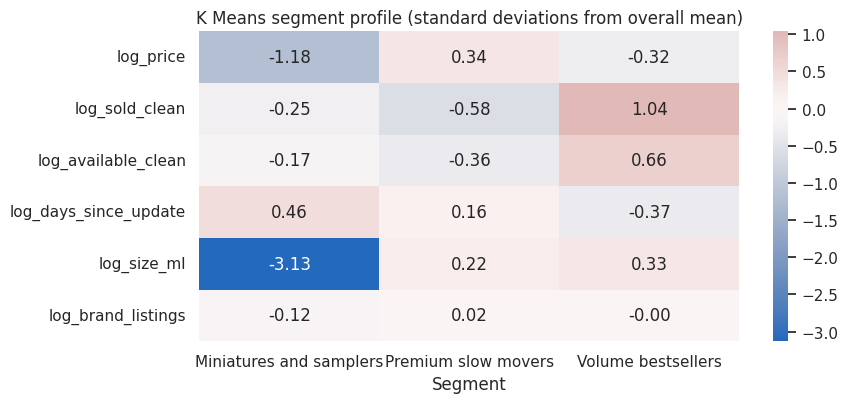

In [37]:
z = df.groupby("segment")[numeric_features].mean()
z = (z - df[numeric_features].mean()) / df[numeric_features].std()

plt.figure(figsize=(9, 4.2))
sns.heatmap(z.T, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("K Means segment profile (standard deviations from overall mean)")
plt.xlabel("Segment")
save("fig08_cluster_profile.png")

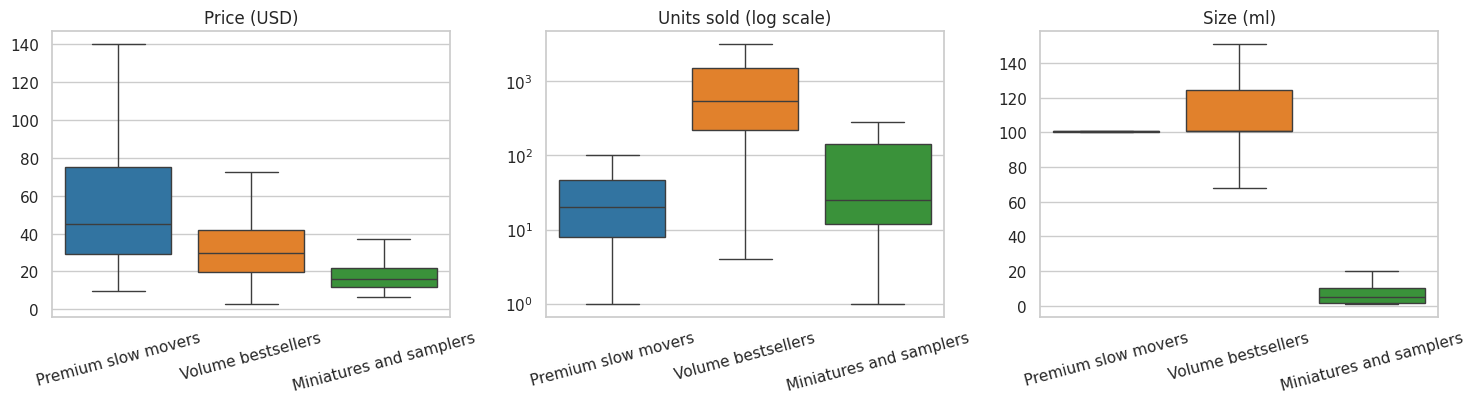

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c, t in zip(axes, ["price", "sold_clean", "size_ml"],
                    ["Price (USD)", "Units sold (log scale)", "Size (ml)"]):
    sns.boxplot(data=df, x="segment", y=c, ax=ax, palette="tab10", showfliers=False)
    ax.set_title(t); ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=15)
    if c == "sold_clean":
        ax.set_yscale("log")
save("fig09_cluster_boxplots.png")

In [39]:
df.to_csv("sales_clustered.csv", index=False)
with open("results.json", "w") as f:
    json.dump(results, f, indent=1,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved sales_clustered.csv and results.json")

Saved sales_clustered.csv and results.json


                         Share of listings  Share of estimated sales value
segment                                                                   
Volume bestsellers                    34.1                            91.9
Premium slow movers                   58.2                             6.9
Miniatures and samplers                7.7                             1.2


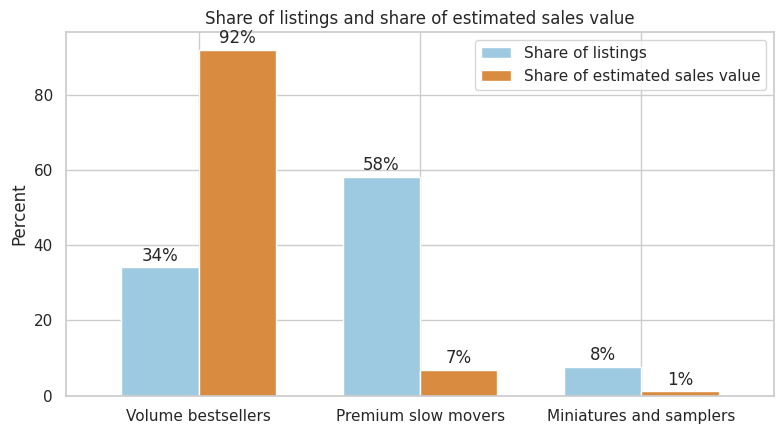

In [40]:
order = ["Volume bestsellers", "Premium slow movers", "Miniatures and samplers"]
share = pd.DataFrame({
    "Share of listings": df["segment"].value_counts(normalize=True) * 100,
    "Share of estimated sales value":
        df.groupby("segment")["est_revenue"].sum() / df["est_revenue"].sum() * 100
}).loc[order]
print(share.round(1))

ax = share.plot(kind="bar", figsize=(8, 4.5), color=["#9ecae1", "#d98c3f"], width=0.7)
ax.set_ylabel("Percent")
ax.set_xlabel("")
ax.set_title("Share of listings and share of estimated sales value")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", padding=2)        # label each bar
save("fig10_exec_summary.png")